# 2016〜2026年 再クラスタリング（旧クラスタ0・6を除外）

前回の10クラスタ結果から旧クラスタ0・6の4,810発言を除外し、残る64,138発言について特徴量から作り直してKMeans（k=10固定）を再学習します。旧結果と元Notebookは変更しません。

In [1]:
from pathlib import Path
import os
import sys

ROOT = Path.cwd()
if not (ROOT / 'analysis').exists():
    ROOT = ROOT.parent
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.matplotlib'))
Path(os.environ['MPLCONFIGDIR']).mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
from matplotlib import font_manager
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(ROOT))
from clustering_2016 import (
    FIXED_K, RANDOM_STATE, apply_manual_labels, cluster_details, compare_k,
    export_results, reduce_dimensions, vectorize,
)

sns.set_theme(style='whitegrid')
mac_font_paths = list(Path('/System/Library/Fonts').glob('*角*W3.ttc'))
if not mac_font_paths:
    raise FileNotFoundError('macOSのヒラギノ角ゴシック W3が見つかりません')
font_manager.fontManager.addfont(str(mac_font_paths[0]))
MAC_JAPANESE_FONT = font_manager.FontProperties(fname=str(mac_font_paths[0])).get_name()
plt.rcParams['font.family'] = MAC_JAPANESE_FONT
plt.rcParams['axes.unicode_minus'] = False
SOURCE = ROOT / 'analysis/clustering_2016_2026/speech_clusters.csv'
OUTPUT_DIR = ROOT / 'analysis/clustering_2016_2026_excluding_0_6'
EXCLUDED_CLUSTERS = {0, 6}
print(f'Matplotlib font: {MAC_JAPANESE_FONT} ({mac_font_paths[0]})')
RANDOM_STATE

Matplotlib font: Hiragino Sans (/System/Library/Fonts/ヒラギノ角ゴシック W3.ttc)


42

## 1. 旧クラスタ0・6を除外

前回結果のクラスタ番号を `previous_cluster` として保存し、除外対象と再学習対象を分離します。

In [2]:
previous = pd.read_csv(SOURCE, encoding='utf-8-sig', parse_dates=['date'])
assert len(previous) == 68948
assert previous['speechID'].is_unique
assert set(previous['cluster']) == set(range(10))
previous = previous.rename(columns={'cluster': 'previous_cluster', 'cluster_label': 'previous_cluster_label'})
exclude_mask = previous['previous_cluster'].isin(EXCLUDED_CLUSTERS)
excluded = previous.loc[exclude_mask].copy()
df = previous.loc[~exclude_mask].copy().reset_index(drop=True)
df['review_flags'] = df['review_flags'].fillna('')
df['year'] = df['year'].astype('int16')
df['month'] = df['date'].dt.to_period('M').astype(str)
assert len(excluded) == 4810
assert len(df) == 64138
assert not df['previous_cluster'].isin(EXCLUDED_CLUSTERS).any()
audit = pd.DataFrame({'category': ['excluded_cluster_0', 'excluded_cluster_6', 'excluded_total', 'recluster_input'], 'count': [(excluded['previous_cluster'] == 0).sum(), (excluded['previous_cluster'] == 6).sum(), len(excluded), len(df)]})
display(audit)
display(pd.crosstab(previous['year'], exclude_mask, colnames=['excluded']).rename(columns={False: 'kept', True: 'excluded'}))

,category,count
0,excluded_cluster_0,2310
1,excluded_cluster_6,2500
2,excluded_total,4810
3,recluster_input,64138


excluded,kept,excluded
year,,
2016,5593,335
2017,5735,548
2018,6825,609
2019,5422,563
2020,7246,810
2021,5764,505
2022,6102,349
2023,5440,304
2024,5618,278


## 2. 特徴量を再作成

除外後の64,138発言だけでTF-IDF語彙とSVDを再学習します。旧モデルのベクトルや重心は再利用しません。

In [3]:
vectorizer, tfidf = vectorize(df)
svd, reduced = reduce_dimensions(tfidf)
print(f'TF-IDF: {tfidf.shape[0]:,} rows × {tfidf.shape[1]:,} features')
print(f'SVD explained variance: {svd.explained_variance_ratio_.sum():.1%}')
print('Zero vectors: 0')

TF-IDF: 64,138 rows × 20,000 features
SVD explained variance: 10.6%
Zero vectors: 0


## 3. KMeans再学習（10クラスタ固定）

In [4]:
scores, models = compare_k(reduced, candidates=[FIXED_K])
model = models[FIXED_K]
print(f'Fixed k={FIXED_K}')
display(scores.style.format({'silhouette': '{:.4f}', 'inertia': '{:,.1f}'}))

Fixed k=10


,k,silhouette,inertia,smallest_cluster,largest_cluster
0,10,0.0338,"51,158.4",2913,13416


## 4. 新クラスタの解釈

,cluster,provisional_label,count,ratio,top_terms,representative_speech_ids
0,0,行う・判断・致す,11268,17.6%,行う | 判断 | 致す | 承知 | 検討 | 議論 | 場合 | 先程 | よる | 関する | 答え | 得る,121005261X00820221129_081 | 119805261X00920190218_381 | 119805261X01320190225_153 | 119605261X00420180202_131 | 121205261X00620231122_155
1,1,感染・接種・ワクチン,3875,6.0%,感染 | 接種 | ワクチン | 検査 | 医療 | 対策 | 状況 | 体制 | 拡大 | 感染 拡大 | コロナ | 感染症,120405261X01120210216_002 | 120805261X01020220204_002 | 120805261X00820220202_030 | 120105261X02420200520_002 | 120805261X01920220526_046
2,2,政治・自民党・議員,4184,6.5%,政治 | 自民党 | 議員 | 資金 | 政治 資金 | 議論 | 国民 | 政党 | 選挙 | 収支 | 総裁 | 団体,121305261X01720240422_054 | 121305261X00720240209_294 | 121605261X00120241205_209 | 121305261X00720240209_302 | 121305261X00920240214_018
3,3,経済・政策・賃金,5930,9.2%,経済 | 政策 | 賃金 | 日本 | 成長 | 上がる | 価格 | 物価 | 企業 | よる | 投資 | 賃上げ,121905261X00720251210_380 | 121305261X00320240205_016 | 121305261X01420240226_314 | 121205261X00720231124_175 | 119805261X01320190225_170
4,4,出る・委員会・宜しい,13416,20.9%,出る | 委員会 | 宜しい | 願う | 委員長 | 報告 | 事実 | 呼ぶ | 受ける | 知る | 安倍 | 今日,119605261X01620180222_291 | 120105261X01420200219_508 | 119505261X00320171128_235 | 119605261X01320180219_248 | 119605261X00320180130_267
5,5,支援・地域・参る,7816,12.2%,支援 | 地域 | 参る | 進める | 取り組み | よる | 取り組む | 致す | 行う | 整備 | 事業 | 自治体,119005261X01420160218_162 | 119005261X01420160218_158 | 121105261X00620230203_028 | 119805261X01020190220_551 | 120105261X01320200218_409
6,6,予算・年度・補正,3419,5.3%,予算 | 年度 | 補正 | 補正 予算 | 令和 | 令和 年度 | 計上 | 基金 | 審議 | 対策 | 年度 予算 | 予備費,122105261X01120260313_074 | 122105261X00420260303_304 | 122105261X00220260227_078 | 121105261X01320230222_271 | 121905261X00620251209_246
7,7,日本・アメリカ・我が国,5920,9.2%,日本 | アメリカ | 我が国 | 安全 | 日米 | 安全 保障 | 保障 | 会談 | 米国 | 世界 | 対する | 中国,121605261X00320241210_036 | 121705261X01220250218_172 | 121105261X00320230131_307 | 121705261X00220250131_033 | 119305261X00220170126_006
8,8,負担・制度・子供,5397,8.4%,負担 | 制度 | 子供 | 財源 | 軽減 | 子育て | 社会保障 | 給付 | 消費税 | 無償化 | 支援 | 議論,119805261X01320190225_304 | 121605261X00420241211_164 | 120105261X00220200127_057 | 119605261X00520180205_127 | 122105261X01020260312_187
9,9,調査・行う・結果,2913,4.5%,調査 | 行う | 結果 | 調査 行う | 委員会 | 調査 結果 | 報告 | 統計 | 致す | 関する | 受ける | よる,120405261X01720210301_359 | 120405261X01720210301_258 | 120405261X01520210222_238 | 119705261X00420181126_118 | 120405261X01820210302_119


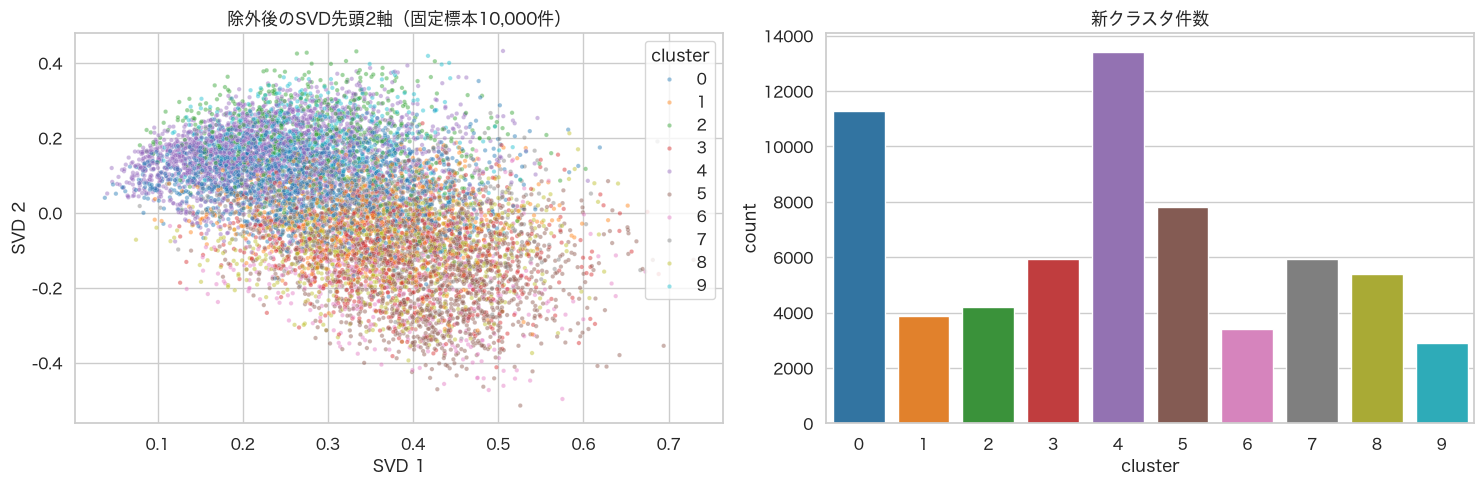

In [5]:
assignments, summary = cluster_details(df, tfidf, reduced, vectorizer, model)
display(summary.style.format({'ratio': '{:.1%}'}))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_sample = assignments.sample(n=min(10000, len(assignments)), random_state=RANDOM_STATE)
plot_idx = plot_sample.index.to_numpy()
sns.scatterplot(x=reduced[plot_idx, 0], y=reduced[plot_idx, 1], hue=plot_sample['cluster'], palette='tab10', s=10, alpha=.45, legend='full', ax=axes[0])
axes[0].set(title='除外後のSVD先頭2軸（固定標本10,000件）', xlabel='SVD 1', ylabel='SVD 2')
sns.barplot(data=summary, x='cluster', y='count', hue='cluster', palette='tab10', legend=False, ax=axes[1])
axes[1].set_title('新クラスタ件数')
plt.tight_layout();

In [6]:
for cluster_id in summary['cluster']:
    row = summary.loc[summary['cluster'].eq(cluster_id)].iloc[0]
    members = assignments.loc[assignments['cluster'].eq(cluster_id)]
    representatives = members.nsmallest(5, 'centroid_distance')[['speechID', 'date', 'year', 'speaker', 'speech_cleaned', 'centroid_distance']]
    top_speakers = members['speaker'].value_counts().head(5).rename_axis('speaker').reset_index(name='count')
    print(f"\nNew cluster {cluster_id}: {row['provisional_label']} ({row['count']:,}件)")
    print(f"特徴語: {row['top_terms']}")
    display(top_speakers, representatives)


New cluster 0: 行う・判断・致す (11,268件)
特徴語: 行う | 判断 | 致す | 承知 | 検討 | 議論 | 場合 | 先程 | よる | 関する | 答え | 得る


,speaker,count
0,安倍晋三,749
1,岸田文雄,747
2,加藤勝信,376
3,石破茂,238
4,菅義偉,237


,speechID,date,year,speaker,speech_cleaned,centroid_distance
36656,121005261X00820221129_081,2022-11-29,2022,岸田文雄,まず、被害を受けられている方をどの範囲まで救えるかという部分につきまして、先ほど申し上げたよ...,0.798933
21335,119805261X00920190218_381,2019-02-18,2019,山下貴司,お答えいたします。 本当に、児童虐待に関しましては、深刻な問題であるというふうに法務省は受け...,0.801543
19676,119805261X01320190225_153,2019-02-25,2019,柴山昌彦,先ほど経産大臣からもあったとおり、今回、御指摘のあるセンターについては、当事者の合意による紛...,0.805749
17463,119605261X00420180202_131,2018-02-02,2018,加藤勝信,今総理が御答弁いたしましたように、正規と非正規の間の不合理な待遇差の解消を目指していく、また...,0.807498
43149,121205261X00620231122_155,2023-11-22,2023,橘幸信,山岡先生にお答え申し上げます。 私ども衆議院法制局は、与党、野党を問わずに、先生方から頂戴し...,0.811442



New cluster 1: 感染・接種・ワクチン (3,875件)
特徴語: 感染 | 接種 | ワクチン | 検査 | 医療 | 対策 | 状況 | 体制 | 拡大 | 感染 拡大 | コロナ | 感染症


,speaker,count
0,加藤勝信,318
1,田村憲久,208
2,後藤茂之,177
3,菅義偉,176
4,岸田文雄,175


...

,speaker,count
0,岸田文雄,445
1,安倍晋三,325
2,石破茂,216
3,加藤勝信,151
4,高市早苗,139


,speechID,date,year,speaker,speech_cleaned,centroid_distance
19799,119805261X01320190225_304,2019-02-25,2019,玉木雄一郎,総理、認識が甘いと思いますよ。 まず申し上げたいのは、相対的貧困は、近年、横ばいではなくて微...,0.677405
48428,121605261X00420241211_164,2024-12-11,2024,三木圭恵,野党の多くも、立憲の方も提案されているということで、是非とも、こういった学生の生の声というも...,0.677455
30556,120105261X00220200127_057,2020-01-27,2020,あべ俊子,ありがとうございます。 特に、それと同時に、就業率と出生率というのは実は正の相関関係がござい...,0.680985
17149,119605261X00520180205_127,2018-02-05,2018,玉木雄一郎,総理、年金制度は総合的に考えなければいけないので、引き上げないのであれば、給付水準は引き下げ...,0.687334
61828,122105261X01020260312_187,2026-03-12,2026,浅野哲,国内でも作れるし他国からも輸入しているんですが、実際、産業界の声を聞いていきますと、四月以降...,0.687945



New cluster 9: 調査・行う・結果 (2,913件)
特徴語: 調査 | 行う | 結果 | 調査 行う | 委員会 | 調査 結果 | 報告 | 統計 | 致す | 関する | 受ける | よる


,speaker,count
0,安倍晋三,135
1,松野博一,117
2,加藤勝信,89
3,岸田文雄,88
4,逢坂誠二,77


,speechID,date,year,speaker,speech_cleaned,centroid_distance
32392,120405261X01720210301_359,2021-03-01,2021,本多平直,ほかの課も調査をすべきではないですかと言っているんですけれども、いかがですか。今回の事案に関...,0.604510
32300,120405261X01720210301_258,2021-03-01,2021,森山浩行,いや、ゆがめられていませんという言い切りは間違いだったんじゃないですか。そういうことですよね...,0.607967
32871,120405261X01520210222_238,2021-02-22,2021,菅義偉,武田大臣の下で徹底して調査、事実関係を明らかにしてほしい、このように思っています。,0.610727
11405,119705261X00420181126_118,2018-11-26,2018,逢坂誠二,先ほど私が例に出した個票は二十九年の旧法のものであるんだと。であるならば、大臣、三十年、こと...,0.613452
32003,120405261X01820210302_119,2021-03-02,2021,野上浩太郎,調査範囲につきましてこちらから提示をしまして、それについては異論がないということで、そして処...,0.615011


## 5. 年別クラスタ構成

2026年は途中年です。

cluster,0,1,2,3,4,5,6,7,8,9
year,,,,,,,,,,
2016,1126,30,455,953,959,563,224,457,611,215
2017,1796,15,126,268,1652,406,177,600,249,446
2018,1272,25,188,363,2430,750,237,679,347,534
2019,913,59,119,484,2025,450,119,492,302,459
2020,1758,1272,251,334,1929,705,248,345,275,129
2021,783,1294,152,302,1301,667,208,358,268,431
2022,804,964,321,822,835,749,349,605,453,200
2023,906,93,460,643,715,726,325,674,796,102
2024,656,26,1452,474,655,984,229,370,578,194


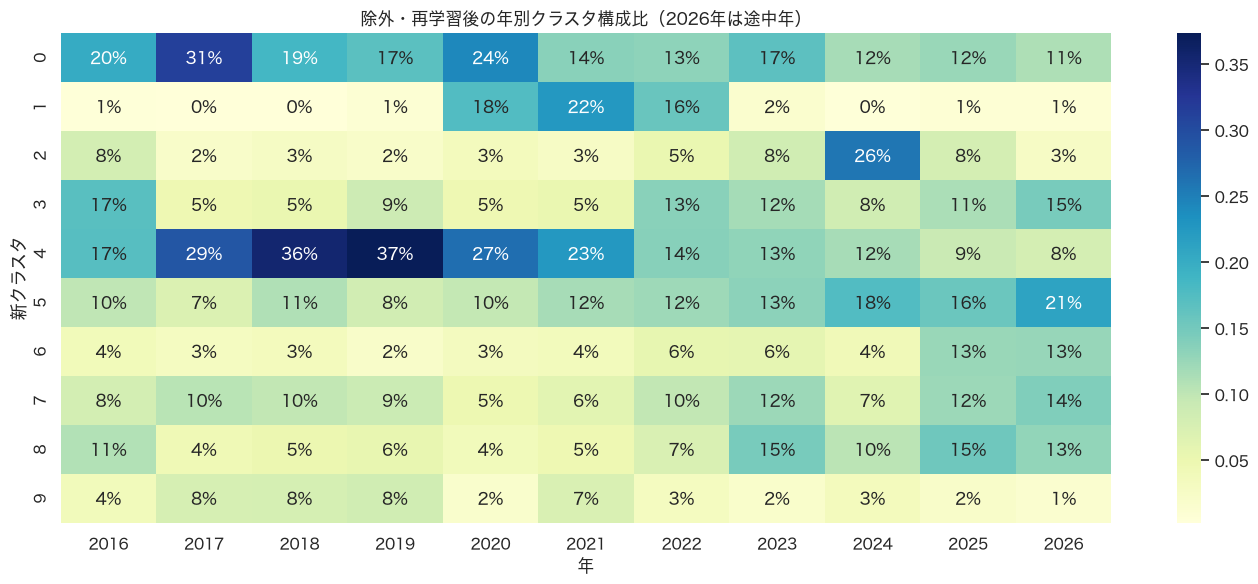

In [7]:
yearly_counts = pd.crosstab(assignments['year'], assignments['cluster'])
yearly_ratio = pd.crosstab(assignments['year'], assignments['cluster'], normalize='index')
display(yearly_counts)
plt.figure(figsize=(14, 6))
sns.heatmap(yearly_ratio.T, cmap='YlGnBu', annot=True, fmt='.0%')
plt.title('除外・再学習後の年別クラスタ構成比（2026年は途中年）')
plt.xlabel('年')
plt.ylabel('新クラスタ')
plt.tight_layout();

## 6. 人手による新ラベル調整

In [8]:
MANUAL_CLUSTER_LABELS = {
    # 0: '社会保障・医療',
    # 1: '外交・安全保障',
}
assignments, summary = apply_manual_labels(assignments, summary, MANUAL_CLUSTER_LABELS)
display(summary[['cluster', 'cluster_label', 'count', 'ratio', 'top_terms']].style.format({'ratio': '{:.1%}'}))

,cluster,cluster_label,count,ratio,top_terms
0,0,行う・判断・致す,11268,17.6%,行う | 判断 | 致す | 承知 | 検討 | 議論 | 場合 | 先程 | よる | 関する | 答え | 得る
1,1,感染・接種・ワクチン,3875,6.0%,感染 | 接種 | ワクチン | 検査 | 医療 | 対策 | 状況 | 体制 | 拡大 | 感染 拡大 | コロナ | 感染症
2,2,政治・自民党・議員,4184,6.5%,政治 | 自民党 | 議員 | 資金 | 政治 資金 | 議論 | 国民 | 政党 | 選挙 | 収支 | 総裁 | 団体
3,3,経済・政策・賃金,5930,9.2%,経済 | 政策 | 賃金 | 日本 | 成長 | 上がる | 価格 | 物価 | 企業 | よる | 投資 | 賃上げ
4,4,出る・委員会・宜しい,13416,20.9%,出る | 委員会 | 宜しい | 願う | 委員長 | 報告 | 事実 | 呼ぶ | 受ける | 知る | 安倍 | 今日
5,5,支援・地域・参る,7816,12.2%,支援 | 地域 | 参る | 進める | 取り組み | よる | 取り組む | 致す | 行う | 整備 | 事業 | 自治体
6,6,予算・年度・補正,3419,5.3%,予算 | 年度 | 補正 | 補正 予算 | 令和 | 令和 年度 | 計上 | 基金 | 審議 | 対策 | 年度 予算 | 予備費
7,7,日本・アメリカ・我が国,5920,9.2%,日本 | アメリカ | 我が国 | 安全 | 日米 | 安全 保障 | 保障 | 会談 | 米国 | 世界 | 対する | 中国
8,8,負担・制度・子供,5397,8.4%,負担 | 制度 | 子供 | 財源 | 軽減 | 子育て | 社会保障 | 給付 | 消費税 | 無償化 | 支援 | 議論
9,9,調査・行う・結果,2913,4.5%,調査 | 行う | 結果 | 調査 行う | 委員会 | 調査 結果 | 報告 | 統計 | 致す | 関する | 受ける | よる


## 7. 出力と最終検証

除外監査表、新しい発言別クラスタ、要約、年別集計を別ディレクトリへ保存します。

In [9]:
assert len(assignments) == 64138
assert assignments['speechID'].is_unique
assert assignments['cluster'].notna().all()
assert set(assignments['cluster']) == set(range(10))
assert summary['count'].sum() == len(assignments)
export_results(assignments, summary, OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
excluded.to_csv(OUTPUT_DIR / 'excluded_previous_clusters_0_6.csv', index=False, encoding='utf-8-sig')
yearly_counts.to_csv(OUTPUT_DIR / 'yearly_cluster_counts.csv', encoding='utf-8-sig')
yearly_ratio.to_csv(OUTPUT_DIR / 'yearly_cluster_ratios.csv', encoding='utf-8-sig')
assert len(pd.read_csv(OUTPUT_DIR / 'speech_clusters.csv')) == 64138
assert len(pd.read_csv(OUTPUT_DIR / 'excluded_previous_clusters_0_6.csv')) == 4810
assert len(pd.read_csv(OUTPUT_DIR / 'cluster_summary.csv')) == 10
print(f'出力先: {OUTPUT_DIR}')
print(f'検証完了: 旧クラスタ0・6を4,810件除外、残り{len(assignments):,}件を10クラスタへ再学習')

出力先: /Users/tasskkiu2/kokkai/analysis/clustering_2016_2026_excluding_0_6
検証完了: 旧クラスタ0・6を4,810件除外、残り64,138件を10クラスタへ再学習
